In [117]:
import pandas as pd
import sqlite3 as sq
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import fiona
import os
import io
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.functions import read_census_table, read_wp23_table

In [118]:
# #to justify not using the building permits to adjust the allocation, compare the county level growth between our TN counties for which we justified it and these KY counties

# counties = ['Stewart County, Tennessee', 'Montgomery County, Tennessee', 'Cheatham County, Tennessee', 'Davidson County, Tennessee', 'Dickson County, Tennessee', 
# 'Maury County, Tennessee', 'Montgomery County, Tennessee', 'Robertson County, Tennessee', 'Rutherford County, Tennessee', 'Trousdale County, Tennessee', 
# 'Williamson County, Tennessee', 'Wilson County, Tennessee', 
# 'Christian County, Kentucky', 'Trigg County, Kentucky']
# #pull 2023 pep
# county_pop = read_census_table('PEP_2023V')
# county_pop_filt = county_pop.loc[(county_pop['NAME'].isin(counties)) & (county_pop['Year'] == '2023')]
# county_pop_comp = county_pop_filt[['NAME', 'Population']].rename(columns = {'Population': 'Population23'})
# #pull 2020 decennial
# county_dec = read_census_table('PL_2020')
# county_dec_filt = county_dec[['NAME', 'Population']].loc[(county_dec['NAME'].isin(counties))].rename(columns = {'Population': 'Population20'})
# #join and examine
# county_comp = county_pop_comp.merge(county_dec_filt, on = 'NAME', how = 'inner')
# county_comp['Real Change'] = county_comp['Population23'] - county_comp['Population20']
# county_comp['Perc Change'] = abs((county_comp['Population23'] - county_comp['Population20'])/county_comp['Population20'])*100
# # county_comp.head()

Read in base year from the Woods and Poole 2023 Vintage Database. The dependencies for these have been run, and the data is written out in the file "Demographic Model Base Year Inputs.ipynb, found in the repository Woods-and-Poole-2023.

In [119]:
dembase = read_wp23_table('DemographicBaseYear')

In [120]:
dembase.head(2)

,NAME,Average Household Size,Population,GQ Population,Housing Units,HH Pop,Last Update Pushed_20260120,Households
0,"Cannon County, Tennessee",2.48,15063,108,6518,14955,None,6030
1,"Cheatham County, Tennessee",2.60,42254,330,17801,41924,None,16125


In [121]:
thelist = ['Trigg County, Kentucky', 'Christian County, Kentucky']
dembase_cos = dembase.loc[dembase['NAME'].isin(thelist)]

In [122]:
dembase_cos

,NAME,Average Household Size,Population,GQ Population,Housing Units,HH Pop,Last Update Pushed_20260120,Households
17,"Christian County, Kentucky",2.62,72032,4918,29405,67114,None,25616
19,"Trigg County, Kentucky",2.42,14369,58,7697,14311,None,5914


In [123]:
file = 'https://www2.census.gov/geo/tiger/TIGER2020/TABBLOCK20/tl_2020_21_tabblock20.zip'
geo = gpd.read_file(file)

In [124]:
geo.head(1)

,STATEFP20,COUNTYFP20,TRACTCE20,BLOCKCE20,GEOID20,NAME20,MTFCC20,UR20,UACE20,UATYPE20,FUNCSTAT20,ALAND20,AWATER20,INTPTLAT20,INTPTLON20,HOUSING20,POP20,geometry
0,21,017,030600,1002,210170306001002,Block 1002,G5040,R,NaN,NaN,S,934479,0,+38.2163349,-084.0124264,6,10,"POLYGON ((-84.02373 38.21494, -84.02316 38.215..."


In [125]:
geo['GEO_ID'] = geo['GEOID20'].astype(str)
geo_join = geo[['GEO_ID', 'geometry']]

In [126]:
geo_join.head(1)

,GEO_ID,geometry
0,210170306001002,"POLYGON ((-84.02373 38.21494, -84.02316 38.215..."


In [127]:
dec = read_census_table('PL_2020_BLKKY')
counties = ['Trigg County', 'Christian County']
dec = dec.loc[dec['County'].isin(counties)]
dec = dec[['GEO_ID', 'Household Population', 'County']]
dec['COUNTY'] = dec['County'] + ", Kentucky"
fips_dict = {'Trigg County, Kentucky': '21221', 'Christian County, Kentucky': '21047'}
dec['COUNTYFP'] = dec['COUNTY'].map(fips_dict)
dec.drop(columns = 'County', inplace = True)
dec['GEO_ID'] = dec['GEO_ID'].str[9:].astype(str)

In [128]:
dec.head(2)

,GEO_ID,Household Population,COUNTY,COUNTYFP
21818,210472001002003,17,"Christian County, Kentucky",21047
21819,210472001002006,0,"Christian County, Kentucky",21047


In [129]:
dec_geo = dec.merge(geo_join, how = "left", on = "GEO_ID")

In [130]:
dec_geo.tail(2)

,GEO_ID,Household Population,COUNTY,COUNTYFP,geometry
2999,212219802001019,0,"Trigg County, Kentucky",21221,"POLYGON ((-87.78198 36.63588, -87.78171 36.637..."
3000,212219802001020,0,"Trigg County, Kentucky",21221,"POLYGON ((-87.76888 36.63583, -87.76842 36.636..."


In [131]:
trigg = dec_geo.loc[dec_geo['COUNTY'] == 'Trigg County, Kentucky'].reset_index(drop = True)
christian = dec_geo.loc[dec_geo['COUNTY'] == 'Christian County, Kentucky'].reset_index(drop = True)

In [132]:
trigg.head()

,GEO_ID,Household Population,COUNTY,COUNTYFP,geometry
0,212219701003003,4,"Trigg County, Kentucky",21221,"POLYGON ((-87.87697 36.96011, -87.87566 36.959..."
1,212219701003006,16,"Trigg County, Kentucky",21221,"POLYGON ((-87.87628 36.95714, -87.87603 36.957..."
2,212219701003009,12,"Trigg County, Kentucky",21221,"POLYGON ((-87.93644 36.92322, -87.93629 36.923..."
3,212219701003013,11,"Trigg County, Kentucky",21221,"POLYGON ((-87.8564 36.92651, -87.85621 36.9266..."
4,212219701003016,31,"Trigg County, Kentucky",21221,"POLYGON ((-87.84762 36.92303, -87.84755 36.923..."


Instead of rounding every block independently, which can result in a county total that's slightly too high or low, this method rounds everything down first and then distributes the remaining people to the blocks with the largest fractional remainders.

In [138]:
#function to round allocations while preserving county totals
def controlled_round(values, target):
    values = np.asarray(values, dtype=float)

    base = np.floor(values).astype(int)
    remainder = int(target - base.sum())

    order = np.argsort(-(values - base), kind='stable')
    base[order[:remainder]] += 1

    return base


#create allocation as the percent each row represents of the total
trigg["Allocation"] = (
    trigg["Household Population"] / trigg["Household Population"].sum()
) * 100

christian["Allocation"] = (
    christian["Household Population"] / christian["Household Population"].sum()
) * 100


#set county-level controls (rounded to whole people)
trigg_control = int(np.rint(
    dembase.loc[dembase["NAME"] == "Trigg County, Kentucky", "HH Pop"].iloc[0]
))

christian_control = int(np.rint(
    dembase.loc[dembase["NAME"] == "Christian County, Kentucky", "HH Pop"].iloc[0]
))


#multiply allocations by county controls and round while preserving totals
trigg["HHPOP"] = controlled_round(
    trigg["Allocation"] / 100 * trigg_control,
    trigg_control
)

christian["HHPOP"] = controlled_round(
    christian["Allocation"] / 100 * christian_control,
    christian_control
)


#quality control
assert trigg["HHPOP"].sum() == trigg_control
assert christian["HHPOP"].sum() == christian_control

print("Trigg County HHPOP:", trigg["HHPOP"].sum())
print("Christian County HHPOP:", christian["HHPOP"].sum())

Trigg County HHPOP: 14311
Christian County HHPOP: 67114


In [139]:
combined = pd.concat([trigg, christian])
combined_geo = gpd.GeoDataFrame(data = combined, geometry = combined.geometry, crs = geo.crs)
combined_geo = combined_geo[['GEO_ID', 'COUNTY', 'COUNTYFP', 'HHPOP', 'geometry']]

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

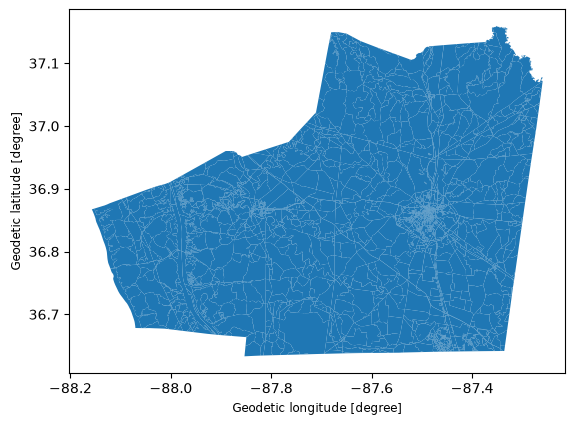

In [140]:
combined_geo.plot()

In [136]:
combined_geo.head(2)

,GEO_ID,COUNTY,COUNTYFP,HHPOP,geometry
0,212219701003003,"Trigg County, Kentucky",21221,4,"POLYGON ((-87.87697 36.96011, -87.87566 36.959..."
1,212219701003006,"Trigg County, Kentucky",21221,16,"POLYGON ((-87.87628 36.95714, -87.87603 36.957..."


In [142]:
combined_geo.to_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\2-outputs\2-geospatial\BaseYear.gpkg", layer="KY_HHPOP", driver="GPKG")